In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import normalize

In [2]:
before = pd.read_csv("../../result/HEK293T_HCT116/coemb/promergeclub_HCT116anchor/HEK293T/HEK293T_epoch0_specific.tsv", sep="\t", index_col=0)
after = pd.read_csv("../../result/HEK293T_HCT116/coemb/promergeclub_HCT116anchor/HEK293T/HEK293T_specific.tsv", sep="\t", index_col=0)

In [3]:
# group by mod and sort
ap = set(pd.read_csv("../../result/HEK293T_HCT116/input/BioPlex-HEK293T.tsv", sep="\t", index_col=0).index)
sec = set(pd.read_csv("../../result/HEK293T_HCT116/input/SECMX-HEK293T.tsv", sep="\t", index_col=0).index)
overlap = ap & sec
ap_unique = ap - overlap
sec_unique = sec - overlap
genes = sorted(ap_unique) + sorted(sec_unique) + sorted(overlap)

before = before.loc[genes]
after = after.loc[genes]

In [4]:
color = (
    ['tab:blue']*len(ap_unique)
    +['tab:red']*len(sec_unique)
    +['tab:orange']*len(overlap)
)
gene_label = pd.Series(
    (
        ['AP-MS only']*len(ap_unique)
        +['SEC-MS only']*len(sec_unique)
        +['Both']*len(overlap)
    ),
    index=genes
)

In [5]:
# premute order to avoid one color dominate
rng = np.random.default_rng(1)
idx = rng.permutation(len(color))
before = before.iloc[idx]
after = after.iloc[idx]
color = np.array(color)[idx]

In [6]:
reducer = umap.UMAP(random_state=1)
embedding_before = reducer.fit_transform(before)

reducer = umap.UMAP(random_state=1)
embedding_after = reducer.fit_transform(after)

/home/jig049/miniforge3/envs/cellmap/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/home/jig049/miniforge3/envs/cellmap/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [7]:
def clustering_stat(
    emb,
    seed=1,
    sample_size=None,
):
    order = np.argsort(np.asarray(emb.index))
    labels = gene_label.loc[emb.index].values[order]
    x = normalize(np.asarray(emb, dtype=float)[order])
    pred = KMeans(
        n_clusters=len(np.unique(labels)),
        n_init=50,
        random_state=seed
    ).fit_predict(x)
    return {
        "NMI": normalized_mutual_info_score(labels, pred),
        "ARI": adjusted_rand_score(labels, pred),
        "Silhouette": silhouette_score(x, labels, metric="cosine", sample_size=sample_size, random_state=seed),
    }

In [8]:
metrics = pd.DataFrame({
    stage: clustering_stat(emb)
    for stage, emb in [("before", before), ("after", after)]
}).T

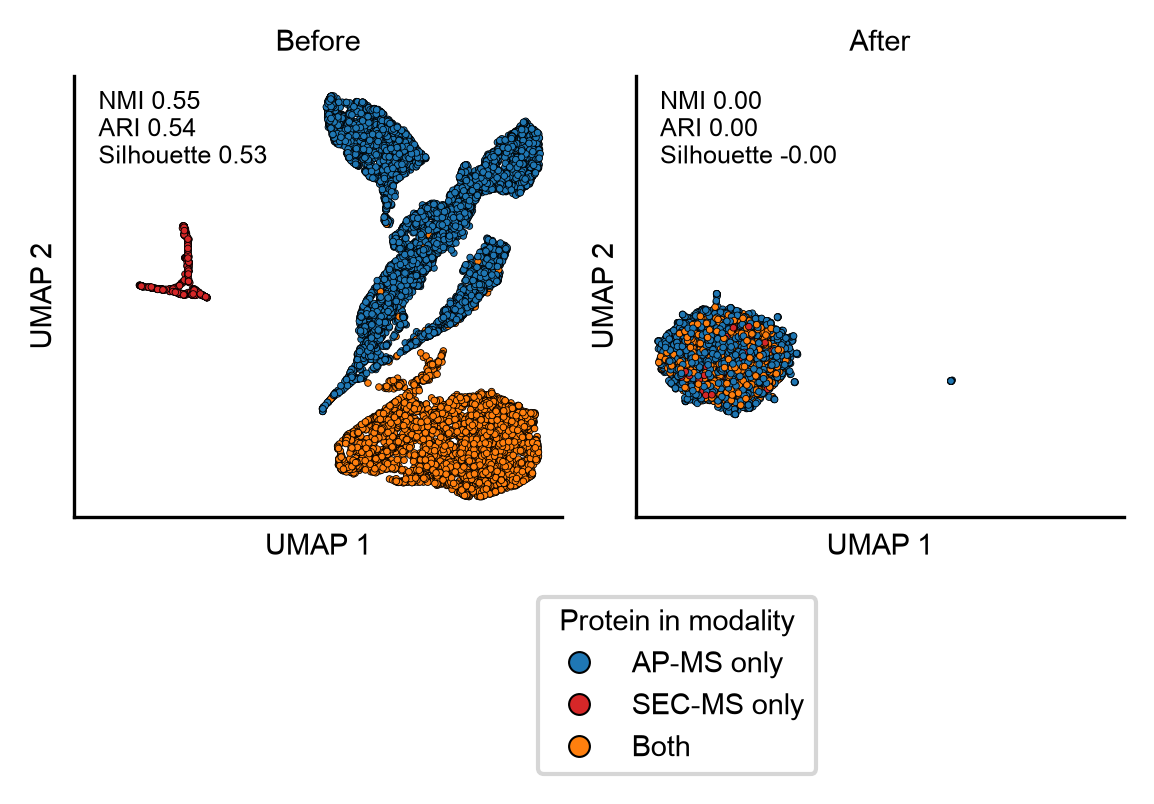

In [9]:
plt.style.use("/home/jig049/misc/style.mplstyle")
fig, axes = plt.subplots(
    nrows=1, ncols=2,
    sharex=True, sharey=True,
    gridspec_kw={"hspace":0.1, "wspace":0.15},
    figsize=(4, 2), dpi=300
)
fig.subplots_adjust(left=0.105, right=0.98, bottom=0.245, top=0.98)

axes[0].scatter(
    embedding_before[:, 0],
    embedding_before[:, 1],
    s=10,
    c=color,
    edgecolors='black',
    lw=0.2,
    marker='.')
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')
axes[0].set_title("Before")

axes[1].scatter(
    embedding_after[:, 0],
    embedding_after[:, 1],
    s=10,
    c=color,
    edgecolors='black',
    lw=0.2,
    marker='.')
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
axes[1].set_title("After")

for ax, stage in zip(axes, ["before", "after"]):
    row = metrics.loc[stage]
    ax.text(
        0.05, 0.97,
        "NMI {:.2f}\nARI {:.2f}\nSilhouette {:.2f}".format(row["NMI"], row["ARI"], row["Silhouette"]),
        transform=ax.transAxes,
        va='top',
        ha='left',
        fontsize=6
    )

for ax in axes.flatten():
    ax.spines[['top', 'right']].set_visible(False)

group_colors = ['tab:blue', 'tab:red', 'tab:orange']
group_labels = ['AP-MS only', 'SEC-MS only', 'Both']
handles = [mlines.Line2D([], [], color=group_colors[i], marker='.', 
        linestyle='None', markersize=10,
        markeredgecolor='black',
        markeredgewidth=0.5, label=group_labels[i]) for i in range(3)]
axes[1].legend(handles=handles, title="Protein in modality", bbox_to_anchor=(0.4, -0.15))
    
plt.savefig("./figS2_before_after.pdf", bbox_inches="tight", transparent=True)